# Week 6 Day 5: Mini Project - Customer Segmentation

End-to-end unsupervised learning project utilizing a customer dataset for cleaning, feature scaling, elbow analysis, KMeans clustering, and cluster interpretation.

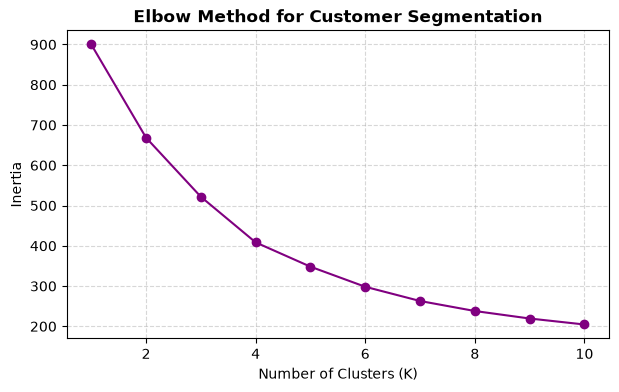

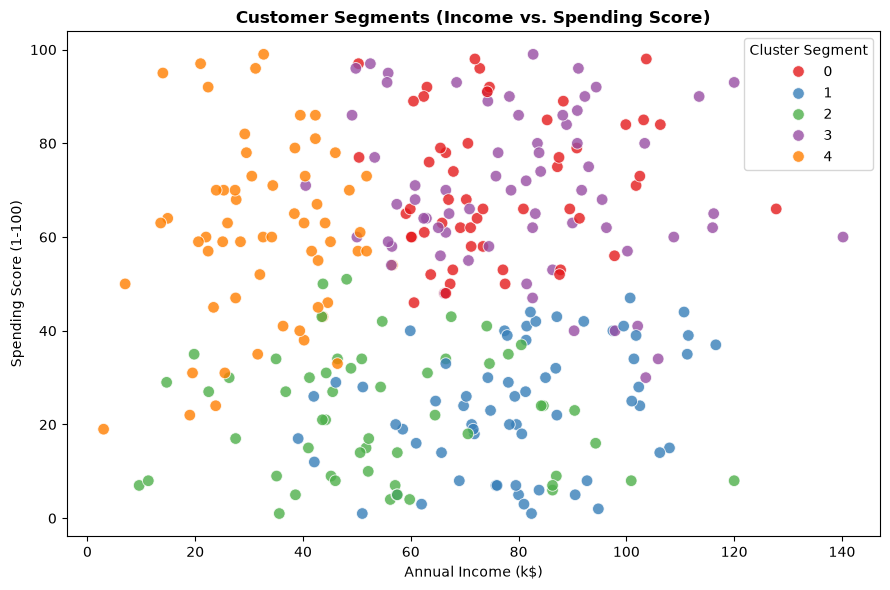

--- Cluster Profiles (Mean Values) ---
               Age  Annual_Income_k$  Spending_Score_1_100
Cluster                                                   
0        56.055556         76.211111             70.611111
1        56.234375         79.743750             23.781250
2        29.072727         54.956364             22.072727
3        27.926471         80.169118             70.235294
4        45.949153         33.016949             60.864407


In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Ensure output directory exists
output_dir = "saved_charts"
os.makedirs(output_dir, exist_ok=True)

# 1. Load / Simulate Customer Dataset
np.searchseed = 42
n_samples = 300

data = {
    "CustomerID": range(1, n_samples + 1),
    "Age": np.random.randint(18, 70, size=n_samples),
    "Annual_Income_k$": np.random.normal(65, 25, size=n_samples).round(1),
    "Spending_Score_1_100": np.random.randint(1, 100, size=n_samples),
}
df = pd.DataFrame(data)

# Introduce synthetic missing values to test cleaning workflow
df.loc[10:14, "Annual_Income_k$"] = np.nan

# 2. Data Cleaning & Preprocessing
imputer = SimpleImputer(strategy="median")
df["Annual_Income_k$"] = imputer.fit_transform(df[["Annual_Income_k$"]])

# Select features for clustering
features = ["Age", "Annual_Income_k$", "Spending_Score_1_100"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Elbow Method to Determine Optimal K
inertia = []
for k in range(1, 11):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia, marker="o", linestyle="-", color="purple")
plt.title("Elbow Method for Customer Segmentation", fontweight="bold")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig(
    os.path.join(output_dir, "Day5_Customer_Elbow.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# 4. Apply Optimal KMeans (e.g., K = 5 segments)
optimal_k = 5
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Cluster"] = kmeans_final.fit_predict(X_scaled)

# 5. Visualize Customer Segments
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Annual_Income_k$",
    y="Spending_Score_1_100",
    hue="Cluster",
    palette="Set1",
    s=70,
    alpha=0.8,
)
plt.title("Customer Segments (Income vs. Spending Score)", fontweight="bold")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster Segment")
plt.tight_layout()

cluster_chart_path = os.path.join(output_dir, "Day5_Customer_Segments.png")
plt.savefig(cluster_chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 6. Cluster Profiling & Statistical Summary
cluster_summary = df.groupby("Cluster")[features].mean()
print("--- Cluster Profiles (Mean Values) ---")
print(cluster_summary)